# 04 · Program-memory lifetime — Fig. 4

Paper section on the storage delay. A delay $\tau$ is inserted on Alice's and Bob's qubits between
storage and retrieval (input $\lvert+\rangle$, program $\mathbb 1$). `FakeKingston` applies $T_1/T_2$
relaxation during the delay.

Model (Eq. 4): a noisy Bell pair $\rho^{(\lambda)}_{AB}=(1-\lambda)\lvert\phi^+\rangle\langle\phi^+\rvert+\lambda\,\mathbb 1/d^2$
equals depolarising noise on Bob, which commutes with Alice's measurement. Hence

$$p_{\rm succ}(\tau)=p(d,k),\qquad \mathcal F(\tau)=1-\frac{d-1}{d}\lambda(\tau),\qquad \lambda(\tau)=1-e^{-\tau/\tau_c},$$

so the fidelity decays exponentially to $1/d$ while the success probability stays flat.

Runtime: about 6 min.

In [1]:
# Load the shared settings and functions (00_core.ipynb must be in the same folder)
%run ./00_core.ipynb

FakeKingston: 156 qubits, native gates ['cz', 'delay', 'id', 'if_else', 'measure', 'measure_2', 'reset', 'rz', 'sx', 'x']
core loaded


In [2]:
DELAYS_US = (0, 50, 100, 150, 200)

res_mem = {}
for method in METHODS:
    for k in KS:
        for tau in DELAYS_US:
            res_mem[(method, k, tau)] = run_single_qubit(k, method, "noisy", in_state="+",
                                                         delay_us=tau or None)
        print(f"{method:<9} k={k}: F(tau) = " +
              "  ".join(f"{res_mem[(method, k, t)]['F']:.3f}" for t in DELAYS_US))

qsd       k=1: F(tau) = 0.943  0.660  0.557  0.507  0.521
qsd       k=2: F(tau) = 0.907  0.661  0.554  0.530  0.508
qsd       k=3: F(tau) = 0.849  0.647  0.561  0.502  0.503
qsd       k=4: F(tau) = 0.616  0.551  0.519  0.498  0.524
qsd       k=5: F(tau) = 0.490  0.501  0.497  0.509  0.506
isometry  k=1: F(tau) = 0.935  0.664  0.556  0.515  0.504
isometry  k=2: F(tau) = 0.913  0.656  0.567  0.513  0.513
isometry  k=3: F(tau) = 0.893  0.658  0.554  0.525  0.509
isometry  k=4: F(tau) = 0.837  0.628  0.551  0.518  0.510
isometry  k=5: F(tau) = 0.673  0.561  0.530  0.514  0.501


## Fit of the decay time $\tau_c$

$\mathcal F(\tau)=1/d+(\mathcal F_0-1/d)\,e^{-\tau/\tau_c}$, with the offset $\mathcal F_0$ set by the
measurement circuit at $\tau=0$.

In [3]:
from scipy.optimize import curve_fit

def fidelity_model(tau, F0, tau_c, d=D):
    return 1 / d + (F0 - 1 / d) * np.exp(-tau / tau_c)

tau = np.array(DELAYS_US, dtype=float)
fits = {}
print(f"{'method':<9} {'k':>2} | {'F0':>6} {'tau_c (us)':>12}")
print("-" * 36)
for method in METHODS:
    for k in KS:
        F = np.array([res_mem[(method, k, t)]["F"] for t in DELAYS_US])
        sF = np.array([max(res_mem[(method, k, t)]["F_err"], 1e-3) for t in DELAYS_US])
        if F[0] - 1 / D < 0.05:              # no visible decay: circuit noise already gives F ~ 1/d
            print(f"{method:<9} {k:>2} | {F[0]:>6.3f}   no decay to fit (F(0) ~ 1/d)")
            continue
        popt, pcov = curve_fit(fidelity_model, tau, F, p0=(F[0], 60), sigma=sF,
                               bounds=([0, 1], [1, 1e4]))
        fits[(method, k)] = popt
        print(f"{method:<9} {k:>2} | {popt[0]:>6.3f} {popt[1]:>7.1f} ± {np.sqrt(pcov[1, 1]):.1f}")

# Cross-check: the delay dephases both halves of the stored Bell pair, so its coherence
# (and the fidelity of the retrieved |+>) decays at the rate 1/T2(A) + 1/T2(B).
A, B = LAYOUT_1[1][-2], LAYOUT_1[1][-1]
t2 = {}
for name, q in (("A", A), ("B", B)):
    prop = FAKE.qubit_properties(q)
    t2[name] = prop.t2 * 1e6
    print(f"memory qubit {name} = q{q}: T1 = {prop.t1 * 1e6:.0f} us, T2 = {t2[name]:.0f} us")
print(f"expected tau_c = (1/T2_A + 1/T2_B)^-1 = {1 / (1 / t2['A'] + 1 / t2['B']):.1f} us")

method     k |     F0   tau_c (us)
------------------------------------
qsd        1 |  0.943    48.6 ± 2.5
qsd        2 |  0.907    52.9 ± 1.5
qsd        3 |  0.850    54.8 ± 4.1
qsd        4 |  0.616    58.9 ± 14.0
qsd        5 |  0.490   no decay to fit (F(0) ~ 1/d)
isometry   1 |  0.935    49.8 ± 1.3
isometry   2 |  0.913    51.9 ± 1.8
isometry   3 |  0.893    53.5 ± 1.2
isometry   4 |  0.836    52.3 ± 0.6
isometry   5 |  0.672    52.0 ± 3.4
memory qubit A = q38: T1 = 277 us, T2 = 125 us
memory qubit B = q29: T1 = 174 us, T2 = 94 us
expected tau_c = (1/T2_A + 1/T2_B)^-1 = 53.7 us


## Figure 4

Dashed lines connect simulated points; solid lines (bottom) are the exponential fits.

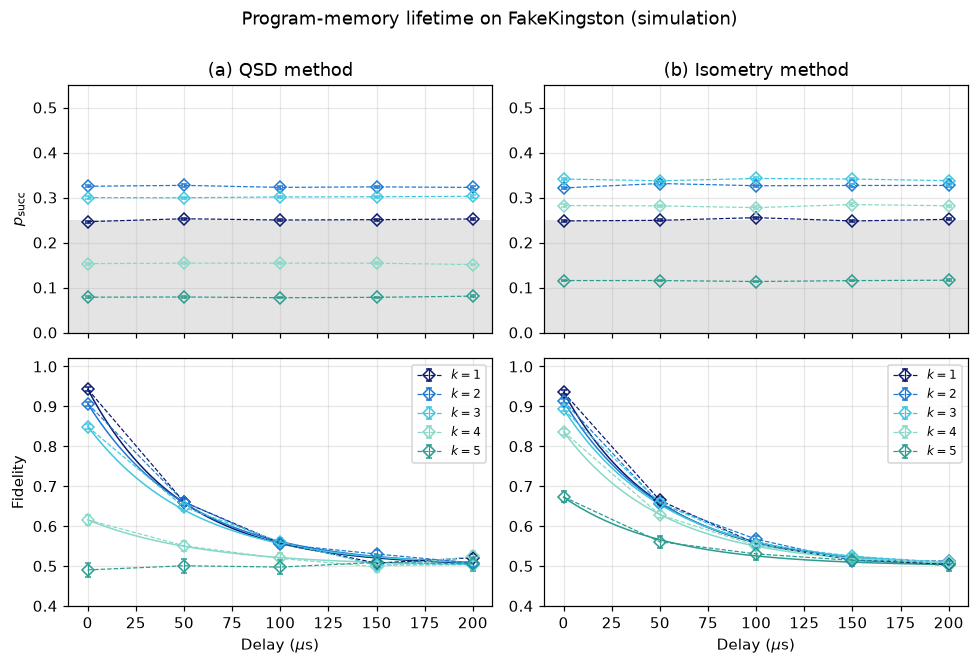

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
t_fine = np.linspace(0, max(DELAYS_US), 200)
for col, method in enumerate(METHODS):
    for k in KS:
        c = K_COLORS[k]
        for row, key in ((0, "p"), (1, "F")):
            y = [res_mem[(method, k, t)][key] for t in DELAYS_US]
            e = [res_mem[(method, k, t)][key + "_err"] for t in DELAYS_US]
            ax[row, col].errorbar(DELAYS_US, y, e, color=c, marker="D", mfc="none", ls="--",
                                  lw=0.8, capsize=2, label=f"$k={k}$")
        if (method, k) in fits:
            ax[1, col].plot(t_fine, fidelity_model(t_fine, *fits[(method, k)]), color=c, lw=1)
    ax[0, col].axhspan(0, 0.25, color="lightgrey", alpha=0.6, lw=0, zorder=0)
    ax[0, col].set(title=f"({'ab'[col]}) {METHOD_STYLE[method]['label']} method", ylim=(0, 0.55))
    ax[1, col].set(xlabel=r"Delay ($\mu$s)", ylim=(0.4, 1.02))
    ax[1, col].legend(loc="upper right")
ax[0, 0].set_ylabel(r"$p_{\rm succ}$")
ax[1, 0].set_ylabel("Fidelity")
fig.suptitle("Program-memory lifetime on FakeKingston (simulation)", y=1.0)
fig.tight_layout()
plt.show()

## Dynamical decoupling in simulation

On hardware, XY4 dynamical decoupling clearly increased the stored-program fidelity. Here we compare
**XY4** with **plain delay padding** of the same idle windows (so both include idle-time noise).

The Aer relaxation model is Markovian (pure exponential $T_1/T_2$), and refocusing pulses cannot undo
Markovian dephasing, so **no DD gain is expected in simulation**. The hardware gain comes from
low-frequency (non-Markovian) noise and coherent errors that this model does not contain.

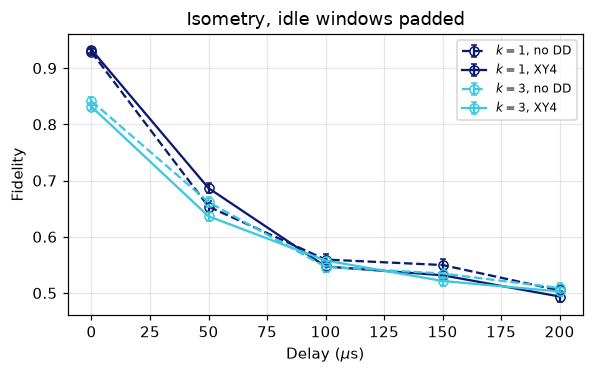

In [5]:
DD_KS = (1, 3)
res_dd = {}
for k in DD_KS:
    for schedule in ("pad", "dd"):
        for t in DELAYS_US:
            res_dd[(k, schedule, t)] = run_single_qubit(k, "isometry", "noisy", in_state="+",
                                                        delay_us=t or None, schedule=schedule)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
for k in DD_KS:
    for schedule, ls in (("pad", "--"), ("dd", "-")):
        ax.errorbar(DELAYS_US, [res_dd[(k, schedule, t)]["F"] for t in DELAYS_US],
                    [res_dd[(k, schedule, t)]["F_err"] for t in DELAYS_US],
                    color=K_COLORS[k], ls=ls, marker="o", mfc="none", capsize=2,
                    label=f"$k={k}$, {'XY4' if schedule == 'dd' else 'no DD'}")
ax.set(xlabel=r"Delay ($\mu$s)", ylabel="Fidelity", title="Isometry, idle windows padded")
ax.legend()
fig.tight_layout()
plt.show()